<a href="https://colab.research.google.com/github/Endoefa/ovo/blob/main/Tutorial_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import libraries

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2
from scipy import ndimage # multidimensional image processing
from skimage.color import rgb2hsv # image processing algorithms

1. Read in images
2. Convert to greyscale
3. Histogram equalisation

/tmp/ipykernel_812/538176291.py:32: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(img.ravel(), 256, [0, 256])
/tmp/ipykernel_812/538176291.py:35: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(equ.ravel(), 256, [0, 256])


Text(0.5, 1.0, 'hist equalised')

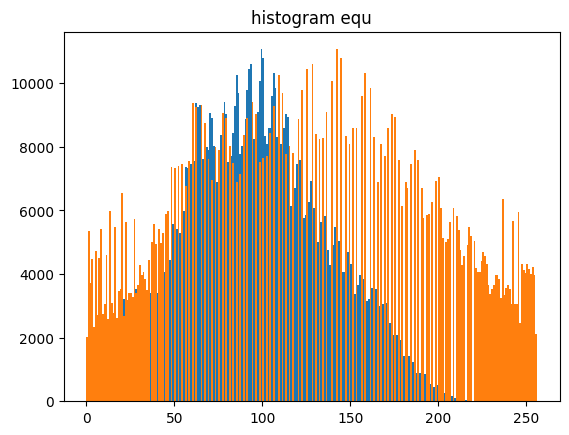

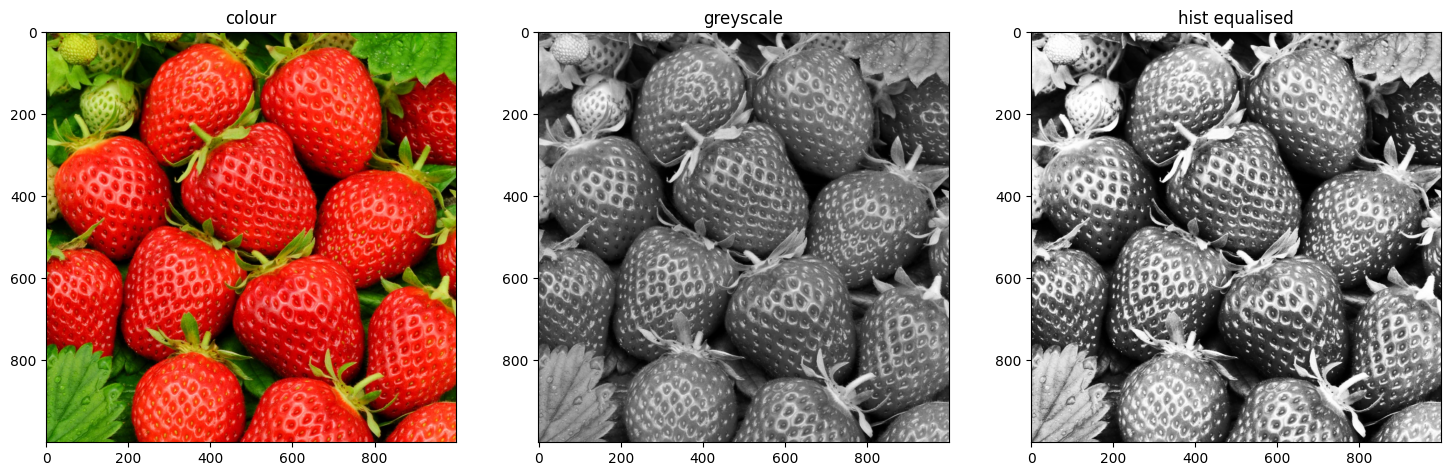

In [9]:
# 读取彩色图片，OpenCV默认按BGR通道顺序读取
img = cv2.imread('/content/strawberry.jpg')

# 先将BGR转换成RGB，再转换成HSV颜色空间
hsv_img = rgb2hsv(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

# 复制原始彩色图片，避免后续修改img时丢失彩色版本
colour = img.copy()

# 将BGR彩色图转换为单通道灰度图
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 另一种读取灰度图的方法：参数0表示直接按灰度读取
# 这一行与前面的“读取彩色图→转换灰度”效果相同，二选一即可
# 此处保留老师的写法，会用重新读取的灰度图覆盖img
img = cv2.imread('/content/strawberry.jpg', 0)

# 对灰度图做直方图均衡化，重新分配灰度值，通常用于增强整体对比度
# 结果保存到equ，原灰度图img保持不变
equ = cv2.equalizeHist(img)


# ===== 对比均衡化前后的灰度直方图 =====

# 新建一张画布
plt.figure()

# img.ravel()：把二维灰度矩阵展开为一维像素数组
# 256：把像素值分成256个统计区间
# [0, 256]：统计范围，覆盖0～255的灰度值
# 横轴表示灰度值，纵轴表示该区间内的像素数量
plt.hist(img.ravel(), 256, [0, 256])

# 在同一张画布上叠加均衡化后图像的直方图，方便比较
plt.hist(equ.ravel(), 256, [0, 256])

# 设置直方图的标题
plt.title("histogram equ")


# ===== 并排展示三张图片 =====

# 新建画布，宽18英寸、高8英寸
plt.figure(figsize=(18, 8))

# 把画布分成1行3列，选中第1个位置
plt.subplot(1, 3, 1)

# 前两个冒号表示保留所有行和列
# ::-1表示反转通道顺序，将BGR变成RGB，供Matplotlib正确显示颜色
plt.imshow(colour[:, :, ::-1])
plt.title("colour")  # 标题：原始彩色图

# 选中第2个位置
plt.subplot(1, 3, 2)

# 用灰度色表显示原始灰度图
plt.imshow(img, cmap="gray")
plt.title("greyscale")  # 标题：灰度图

# 选中第3个位置
plt.subplot(1, 3, 3)

# 用灰度色表显示直方图均衡化后的图像
plt.imshow(equ, cmap="gray")
plt.title("hist equalised")  # 标题：均衡化后的灰度图

Comparing different thresholding methods

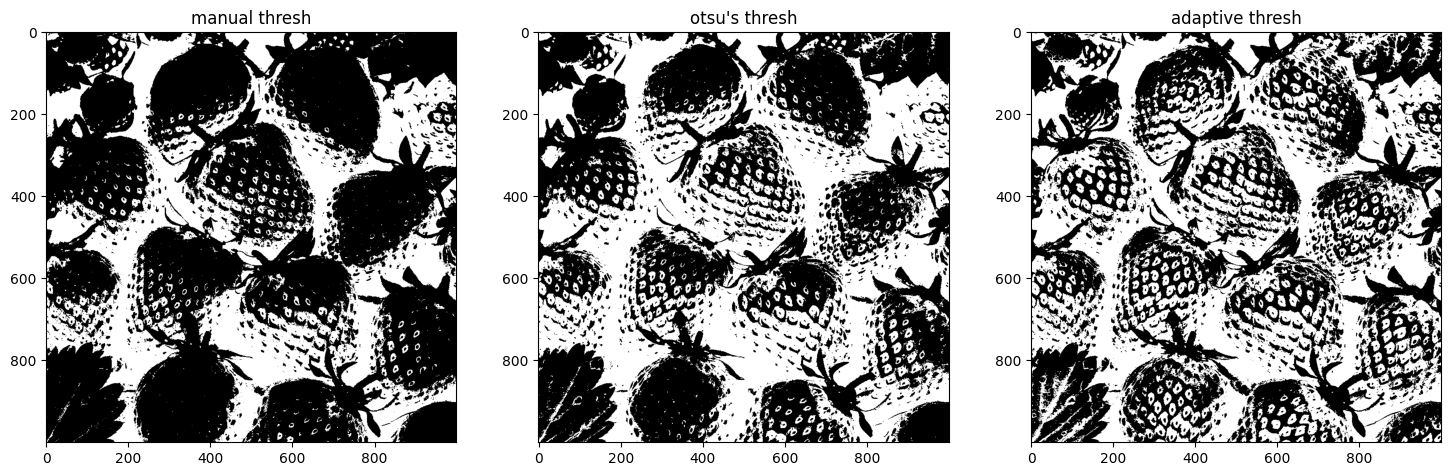

In [5]:
# ===== 方法1：手动设定全局阈值 =====

# 对均衡化后的灰度图equ进行二值化，手动指定阈值为90
# THRESH_BINARY_INV表示反向二值化：
# 像素值 <= 90 → 255（白色）
# 像素值 > 90  → 0（黑色）
# thresh1接收实际使用的阈值，这里是90
# bw1接收生成的黑白图，也就是二值掩膜
thresh1, bw1 = cv2.threshold(
    equ,
    thresh=90,
    maxval=255,
    type=cv2.THRESH_BINARY_INV
)


# ===== 方法2：Otsu自动选择全局阈值 =====

# Otsu根据整张图的灰度分布，自动计算一个阈值
# 因为启用了Otsu，这里传入的127不会作为最终阈值使用
# thresh2接收自动计算出的阈值，bw2接收二值图
# 这里使用普通二值化：大于自动阈值的变白，其余变黑
thresh2, bw2 = cv2.threshold(
    equ,
    thresh=127,
    maxval=255,
    type=cv2.THRESH_OTSU
)


# ===== 方法3：自适应局部阈值 =====

# 使用原始灰度图img，注意前两种方法用的是均衡化后的equ
# 每个像素的阈值由它附近的区域决定，而不是整张图共用一个阈值
bw3 = cv2.adaptiveThreshold(
    img,                            # 输入灰度图
    255,                            # 二值化后的白色像素值
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,  # 用邻域像素的高斯加权平均值计算阈值
    cv2.THRESH_BINARY,               # 大于局部阈值变白，否则变黑
    301,                            # 邻域大小：301×301，必须是大于1的奇数
    3                               # 常数C：局部阈值 = 高斯加权平均值 - 3
)


# ===== 统一黑白方向 =====

# 对uint8二值图取反：0变255，255变0
# 方法1已经是反向二值化，因此这里只反转方法2和方法3
bw2 = np.invert(bw2)
bw3 = np.invert(bw3)


# ===== 并排展示三种结果 =====

# 创建宽18英寸、高8英寸的画布
plt.figure(figsize=(18, 8))

# 画布分成1行3列，在第1个位置展示手动阈值结果
plt.subplot(1, 3, 1)
plt.imshow(bw1, cmap="gray")
plt.title("manual thresh")

# 第2个位置展示Otsu自动阈值结果
plt.subplot(1, 3, 2)
plt.imshow(bw2, cmap="gray")
plt.title("otsu's thresh")

# 第3个位置展示自适应阈值结果
plt.subplot(1, 3, 3)
plt.imshow(bw3, cmap="gray")
plt.title("adaptive thresh")

# 显示画布
plt.show()

Morphological operations for separating stawberries

Text(0.5, 1.0, 'close & erosion2')

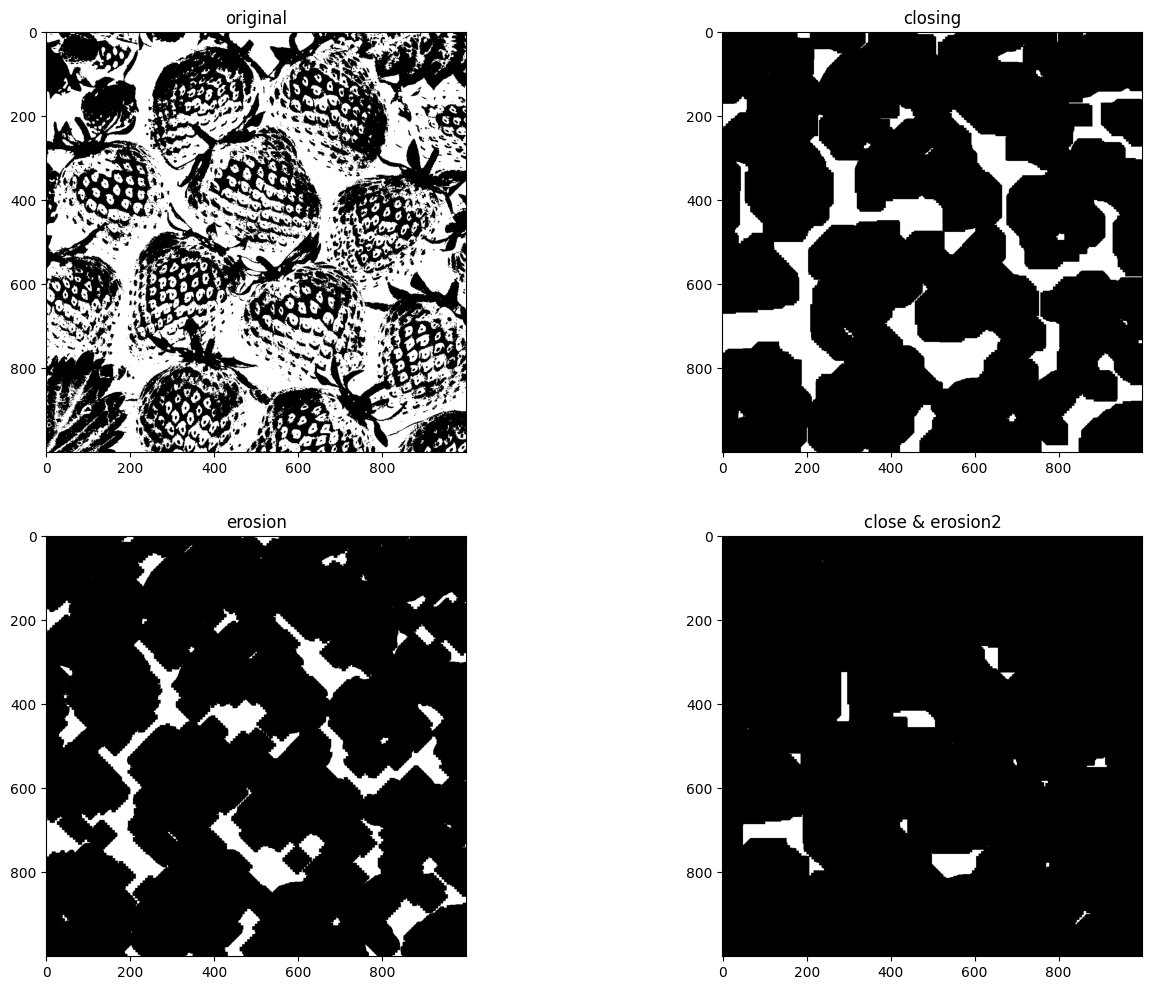

In [6]:
# ===== 第一步：闭运算，填补小孔和小缝隙 =====

# 创建3×3的正方形结构元素，里面全部是1
# uint8表示使用8位无符号整数类型
kernel = np.ones((3, 3), np.uint8)

# 对自适应阈值生成的二值图bw3做闭运算
# 闭运算：先膨胀，再侵蚀
# iterations=4：先连续膨胀4次，再连续侵蚀4次
# 目的：填补白色区域中的小缺口，但也可能连接靠得很近的区域
closing = cv2.morphologyEx(
    bw3, cv2.MORPH_CLOSE, kernel, iterations=4
)


# ===== 第二步：侵蚀，缩小白色区域、切断细连接 =====

# 创建13×13的十字形结构元素
# 中间一整行和一整列为1，其他位置为0
# 用新的结构元素替换之前的kernel
kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (13, 13))

# 在第一次闭运算的结果上连续侵蚀5次
# 目的：让草莓区域缩小，尝试切断草莓之间的连接
# 但处理过强也可能让小草莓完全消失
erosion = cv2.erode(closing, kernel, iterations=5)


# ===== 第三步：再次闭运算，整理侵蚀后的区域 =====

# 创建11×11的全1正方形结构元素
kernel = np.ones((11, 11), np.uint8)

# 在侵蚀结果上做闭运算：先膨胀5次，再侵蚀5次
# 目的：填补残余孔洞和缝隙，让区域更完整
# 注意：这里会覆盖之前的closing变量
closing = cv2.morphologyEx(
    erosion, cv2.MORPH_CLOSE, kernel, iterations=5
)


# ===== 第四步：再次侵蚀，进一步分离区域 =====

# 创建7×7的全1正方形结构元素
kernel = np.ones((7, 7), np.uint8)

# 对第二次闭运算的结果连续侵蚀6次
# 将最终侵蚀结果保存到erosion2
erosion2 = cv2.erode(closing, kernel, iterations=6)


# ===== 第五步：把图像四周宽50像素的区域清零 =====

# 0代表黑色背景
# 以下操作是直接删除边缘区域，不是形态学运算

erosion2[:50, :] = 0    # 前50行，即顶部
erosion2[:, :50] = 0    # 前50列，即左侧
erosion2[-50:, :] = 0   # 最后50行，即底部
erosion2[:, -50:] = 0   # 最后50列，即右侧

# 目的：排除边缘的干扰区域
# 注意：如果真实草莓出现在这些位置，也会被一起删除


# ===== 展示处理结果 =====

# 创建宽16英寸、高12英寸的画布
plt.figure(figsize=(16, 12))

# 分成2行2列，第1个位置：最初的二值掩膜
# 这里的original指处理前的bw3，不是彩色原图
plt.subplot(2, 2, 1)
plt.imshow(bw3, cmap="gray")
plt.title("original")

# 第2个位置：第二次闭运算的结果
plt.subplot(2, 2, 2)
plt.imshow(closing, cmap="gray")
plt.title("closing")

# 第3个位置：第一次侵蚀的结果
plt.subplot(2, 2, 3)
plt.imshow(erosion, cmap="gray")
plt.title("erosion")

# 第4个位置：第二次侵蚀，并清除边缘后的最终结果
plt.subplot(2, 2, 4)
plt.imshow(erosion2, cmap="gray")
plt.title("close & erosion2")

Find centroids of isolated clusters/blobs

There are 19 strawberries


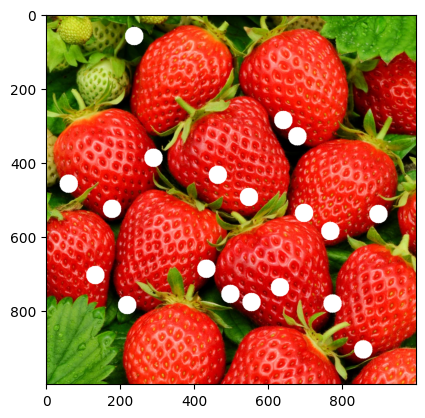

In [7]:
# 复制彩色原图，用来画标记，避免修改原来的colour
display = colour.copy()

# 找出erosion2中的连通区域，并给每个区域分配一个编号
# 0是背景，非零像素（这里是255）属于前景
# 默认按4连通判断：上下左右相连的前景像素属于同一区域
#
# labels：与图像大小相同的编号矩阵
#         背景位置为0，第一个区域的像素为1，第二个区域为2……
# nlabels：找到的区域总数，不包含背景
labels, nlabels = ndimage.label(erosion2)

# 将连通区域的数量作为预测的草莓数量，打印出来
# str(nlabels)：把数字转成字符串，方便和文字拼接
print("There are " + str(nlabels) + " strawberries")


# 计算每个连通区域的质心，也就是按像素值加权的中心位置
# 这里前景像素全部为255，因此等价于计算每个区域的像素坐标平均值
#
# erosion2：用于计算的二值图
# labels：告诉函数每个像素属于哪个区域
# np.arange(nlabels) + 1：生成要计算的区域编号
# 例如有3个区域，就得到[1, 2, 3]，不计算背景0
#
# centroid保存各区域的中心，每个中心的格式是(行, 列)，即(y, x)
centroid = ndimage.center_of_mass(
    erosion2, labels, np.arange(nlabels) + 1
)


# 遍历每个区域的中心，在彩色原图上画一个白色实心圆
for cen in centroid:

    # OpenCV要求坐标顺序为(x, y)，因此要把(行, 列)交换
    # int(...)：将中心的小数坐标转换为整数像素坐标
    center = (int(cen[1]), int(cen[0]))

    display = cv2.circle(
        display,                # 在这张图片上画
        center,                 # 圆心坐标(x, y)
        radius=25,              # 半径25像素
        color=(255, 255, 255),   # 白色，BGR三个通道都为255
        thickness=-1            # -1表示填满圆内部
    )

# 新建画布
plt.figure()

# 将BGR通道顺序反转为RGB，让Matplotlib正确显示颜色
plt.imshow(display[:, :, ::-1])

Use the HSV colour space as an alternative to the RGB colour space

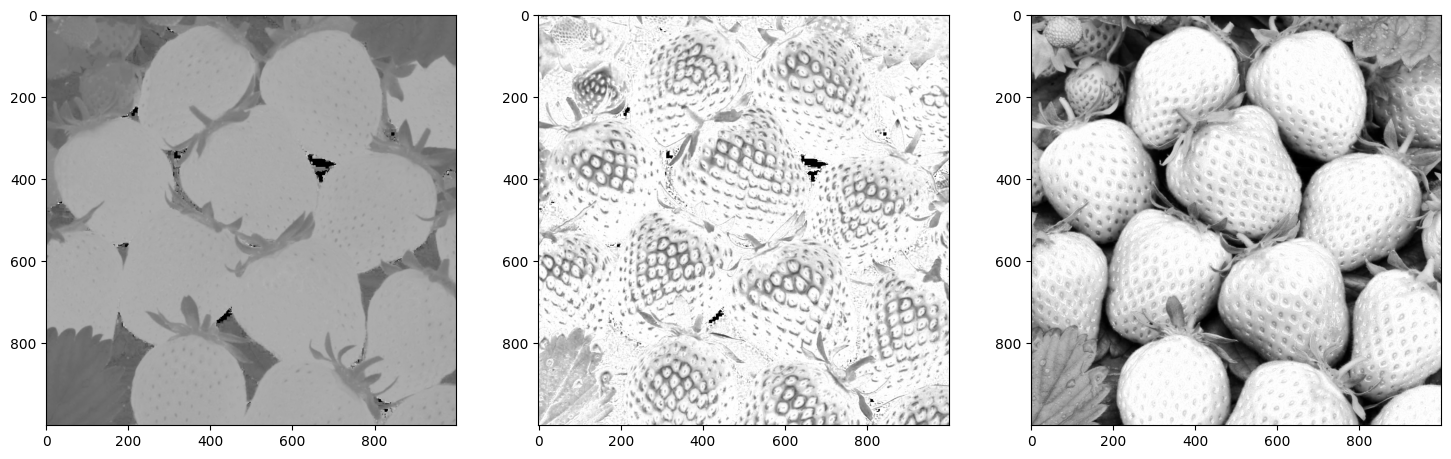

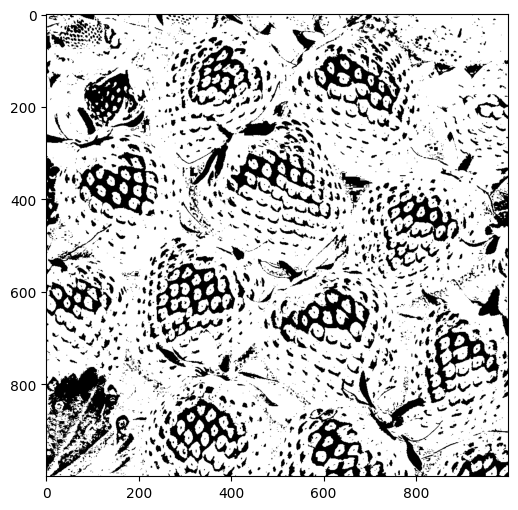

In [8]:
# ===== 分别显示HSV的三个通道 =====

# 创建宽18英寸、高6英寸的画布
plt.figure(figsize=(18, 6))

# 第1个位置：H通道（色相），表示颜色种类
# [:, :, 0]：取所有行、所有列的第0个通道
# cmap="gray"只是把通道数值用明暗展示，不是在做RGB转灰度
plt.subplot(1, 3, 1)
plt.imshow(hsv_img[:, :, 0], cmap="gray")

# 第2个位置：S通道（饱和度），表示颜色的鲜艳程度
# 数值越大，饱和度越高
# 老师选择这个通道进行后面的分割
plt.subplot(1, 3, 2)
plt.imshow(hsv_img[:, :, 1], cmap="gray")

# 第3个位置：V通道（明度），表示颜色的明亮程度
plt.subplot(1, 3, 3)
plt.imshow(hsv_img[:, :, 2], cmap="gray")


# ===== 将S通道转换为OpenCV阈值函数需要的格式 =====

# skimage生成的S通道是0～1的浮点数
# 先乘255，将范围缩放到0～255
# 再转成uint8，供下面的Otsu阈值函数使用
hsv_c = (255 * hsv_img[:, :, 1]).astype(np.uint8)


# ===== 对S通道进行Otsu自动阈值分割 =====

# Otsu自动计算阈值，因此这里填写的128不决定最终阈值
# thresh_hsv：自动计算得到的阈值
# bw_hsv：生成的二值掩膜
# S值大于自动阈值 → 255（白色）
# S值小于或等于自动阈值 → 0（黑色）
thresh_hsv, bw_hsv = cv2.threshold(
    hsv_c,
    thresh=128,
    maxval=255,
    type=cv2.THRESH_OTSU
)


# ===== 显示分割结果 =====

# 创建宽6英寸、高6英寸的画布
plt.figure(figsize=(6, 6))

# 用黑白方式显示二值掩膜
plt.imshow(bw_hsv, cmap="gray")